# 08.3 · Activation functions and loss functions

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/cloudops-one/training-ai-ml/blob/main/modules/08-deep-learning/03-activations-and-losses/lesson.ipynb)

Read the [README](README.md) first. This notebook checks every by-hand number, plots the activations, and shows what happens to a network without them.

In [1]:
# --- data helper: works locally and on Colab -------------------------------
from pathlib import Path
import urllib.request

def data_path(name):
    """Return a local path to data/<name>, downloading from GitHub on Colab."""
    for parent in [Path.cwd(), *Path.cwd().parents]:
        candidate = parent / "data" / name
        if candidate.exists():
            return candidate
    url = f"https://raw.githubusercontent.com/cloudops-one/training-ai-ml/main/data/{name}"
    dest = Path(name)
    if not dest.exists():
        urllib.request.urlretrieve(url, dest)
    return dest

import os
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"        # hide TensorFlow start-up messages
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import warnings; warnings.filterwarnings("ignore")

def sigmoid(z): return 1 / (1 + np.exp(-z))
def relu(z):    return np.maximum(0, z)
def softmax(z):
    e = np.exp(z - np.max(z))          # subtracting the max avoids overflow, same result
    return e / e.sum()

## 1. Activations at −2, 0 and 2

In [2]:
z = np.array([-2.0, 0.0, 2.0])
print(pd.DataFrame({"z": z, "sigmoid": sigmoid(z), "tanh": np.tanh(z), "ReLU": relu(z)}).round(3))

     z  sigmoid   tanh  ReLU
0 -2.0    0.119 -0.964   0.0
1  0.0    0.500  0.000   0.0
2  2.0    0.881  0.964   2.0


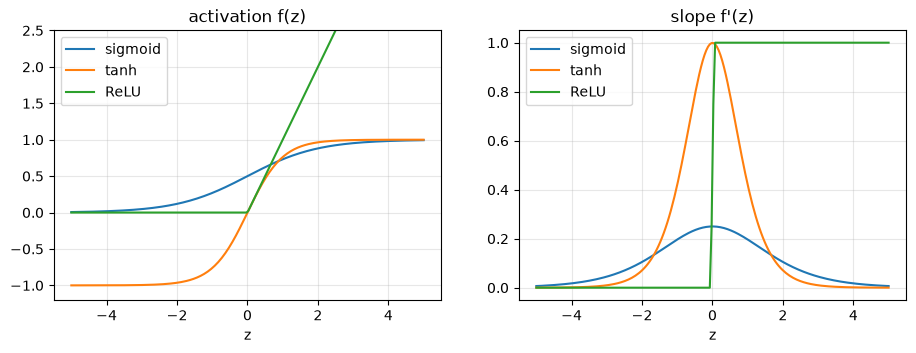

In [3]:
zz = np.linspace(-5, 5, 200)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
for name, f in [("sigmoid", sigmoid), ("tanh", np.tanh), ("ReLU", relu)]:
    axes[0].plot(zz, f(zz), label=name)
    axes[1].plot(zz, np.gradient(f(zz), zz), label=name)
axes[0].set_title("activation f(z)"); axes[1].set_title("slope f'(z)")
for ax in axes: ax.set_xlabel("z"); ax.grid(alpha=.3); ax.legend()
axes[0].set_ylim(-1.2, 2.5); plt.show()

Look at the slopes on the right. Sigmoid's slope is never above 0.25 and is almost zero beyond ±4. Training multiplies slopes layer by layer (lesson 08.4), so many sigmoid layers make the signal fade: the **vanishing gradient**. ReLU's slope is exactly 1 for every positive $z$.

## 2. Softmax

In [4]:
scores = np.array([2.0, 1.0, 0.1])               # mug, cushion, lantern
print("e^z      :", np.exp(scores).round(3), " total:", np.exp(scores).sum().round(3))
print("softmax  :", softmax(scores).round(3), " sums to", softmax(scores).sum())

e^z      : [7.389 2.718 1.105]  total: 11.213
softmax  : [0.659 0.242 0.099]  sums to 1.0


In [5]:
import keras
from keras import layers
keras.utils.set_random_seed(42)      # same starting weights every run (small differences across machines are normal)
print("Keras", keras.__version__, "on", keras.backend.backend())

print("Keras    :", np.asarray(keras.activations.softmax(scores[None, :])).round(3))

Keras 3.15.1 on tensorflow
Keras    : [[0.659 0.242 0.099]]


## 3. Stacked linear layers collapse

In [6]:
x = np.array([1.0, 3.0])
W1 = np.array([[1.0, 2.0], [0.5, -1.0]])
W2 = np.array([[3.0], [1.0]])
h = x @ W1
print("two linear layers :", h, "→", h @ W2)
print("one layer W1@W2   :", (W1 @ W2).ravel(), "→", x @ (W1 @ W2))
print("with ReLU between :", relu(h), "→", relu(h) @ W2)

two linear layers : [ 2.5 -1. ] → [6.5]
one layer W1@W2   : [5.  0.5] → [6.5]
with ReLU between : [2.5 0. ] → [7.5]


## 4. The same collapse on real training

The two-moons dataset needs a curved boundary. Train an identical three-layer network with different hidden activations.

In [7]:
from sklearn.datasets import make_moons
X, y = make_moons(600, noise=0.2, random_state=42)

def moons_accuracy(activation, hidden_layers=2):
    keras.utils.set_random_seed(42)
    model = keras.Sequential([keras.Input((2,))] +
                             [layers.Dense(16, activation=activation) for _ in range(hidden_layers)] +
                             [layers.Dense(1, activation="sigmoid")])
    model.compile(optimizer=keras.optimizers.Adam(0.01), loss="binary_crossentropy", metrics=["accuracy"])
    history = model.fit(X, y, epochs=100, batch_size=32, verbose=0)
    return model, history.history["accuracy"][-1]

from sklearn.linear_model import LogisticRegression
print(f"logistic regression : {LogisticRegression().fit(X, y).score(X, y):.1%}")
models = {}
for act in [None, "sigmoid", "tanh", "relu"]:
    models[act], acc = moons_accuracy(act)
    print(f"hidden activation {str(act):8s}: {acc:.1%}")

logistic regression : 87.5%


hidden activation None    : 87.5%


hidden activation sigmoid : 95.8%


hidden activation tanh    : 96.8%


hidden activation relu    : 97.2%


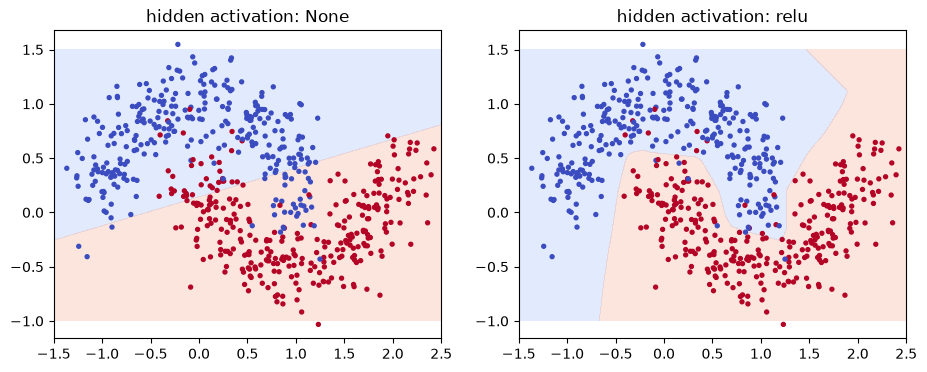

In [8]:
xx, yy = np.meshgrid(np.linspace(-1.5, 2.5, 200), np.linspace(-1, 1.5, 200))
grid = np.c_[xx.ravel(), yy.ravel()]
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, act in zip(axes, [None, "relu"]):
    p = models[act].predict(grid, verbose=0).reshape(xx.shape)
    ax.contourf(xx, yy, p, levels=[0, .5, 1], alpha=.25, cmap="coolwarm")
    ax.scatter(X[:, 0], X[:, 1], c=y, s=8, cmap="coolwarm"); ax.set_title(f"hidden activation: {act}")
plt.show()

The linear network can only draw a straight line, exactly like logistic regression (both 87.5%). With ReLU, the network bends its boundary around the moons.

## 5. Losses by hand, checked against Keras

In [9]:
y_true, y_pred = np.array([3.0, 5.0]), np.array([2.5, 6.0])
print("MSE                    :", ((y_true - y_pred) ** 2).mean(),
      "| Keras:", float(keras.losses.MeanSquaredError()(y_true, y_pred)))

bce = keras.losses.BinaryCrossentropy()
for p in [0.9, 0.1]:
    print(f"BCE, churned, p = {p}   : {-np.log(p):.3f} | Keras: {float(bce(np.array([[1.0]]), np.array([[p]]))):.3f}")

cce = keras.losses.SparseCategoricalCrossentropy()
print(f"CCE, true = cushion    : {-np.log(0.7):.3f} | Keras: {float(cce(np.array([1]), np.array([[0.2, 0.7, 0.1]]))):.3f}")

MSE                    : 0.625 | Keras: 0.625
BCE, churned, p = 0.9   : 0.105 | Keras: 0.105
BCE, churned, p = 0.1   : 2.303 | Keras: 2.303
CCE, true = cushion    : 0.357 | Keras: 0.357


Keras' numbers match the hand calculations (Keras clips probabilities a hair away from 0 and 1, so tiny differences in the last digit are possible).

## 6. How log loss grows

The closer a wrong prediction is to certainty, the faster the loss rises: being 99% sure and wrong costs twice as much as being 90% sure and wrong.

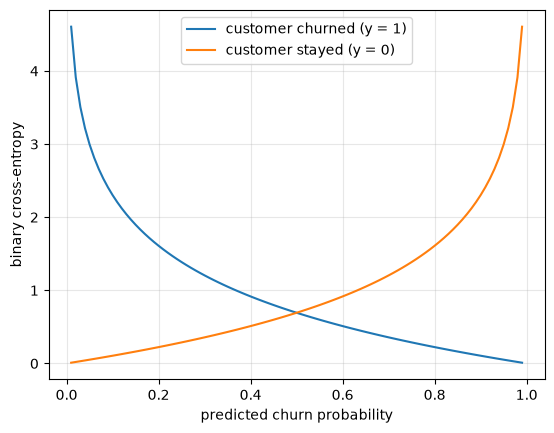

y=1, p=0.10: 2.30   y=1, p=0.01: 4.61


In [10]:
p = np.linspace(0.01, 0.99, 99)
plt.plot(p, -np.log(p), label="customer churned (y = 1)")
plt.plot(p, -np.log(1 - p), label="customer stayed (y = 0)")
plt.xlabel("predicted churn probability"); plt.ylabel("binary cross-entropy")
plt.legend(); plt.grid(alpha=.3); plt.show()
print(f"y=1, p=0.10: {-np.log(0.10):.2f}   y=1, p=0.01: {-np.log(0.01):.2f}")

## Quiz answers

1. A layer without activation is a matrix multiplication; multiplying matrices gives another matrix, so $(xW_1)W_2 = x(W_1W_2)$, a single layer.
2. ReLU: it is cheap, and its slope is 1 for all positive inputs, so gradients do not vanish through many layers.
3. Every output is between 0 and 1 and they sum to exactly 1, so they can be read as probabilities over the classes.
4. Churn: one sigmoid output with binary cross-entropy. Product type out of 10: ten softmax outputs with (sparse) categorical cross-entropy.
5. It is $-\ln$ of the probability given to the true answer. As that probability approaches 0, $-\ln p$ grows without limit, so a confident mistake costs far more than a hesitant one.

**Next:** [08.4 Backpropagation by hand](../04-backpropagation-by-hand/)